# Positioning Extremes: How Long Crowding Lasts

Notebook 03 finds today's crowded trades. The natural next question is **how long they stay crowded**. A crowded trade
that normalises in a week calls for a different stance from one that stays stretched for a quarter.

This notebook studies every crowding episode in the point-in-time history of the daily positioning series:

1. Define episodes: a first cross of ±1.5σ, with a cool-down so one episode counts once
2. Measure duration: business days until positioning is back inside ±0.5σ
3. Track the average path of an episode: how much further it overshoots, and how fast it decays
4. Compare survival by asset class, and longs vs shorts
5. Ask whether the speed going in says anything about the way out
6. Apply it to today: expected remaining life of current extremes

Everything uses **point-in-time** values (notebook 04 explains why).

In [1]:
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()

ASSET_COLORS = {"EQ": qk.VANDA["purple"], "FI": "#3b82f6", "FX": "#10b981", "COM": "#f59e0b"}
NORMAL = 0.5
HORIZONS = [5, 20, 60, 120]

## 1. Episodes

We use daily series only, on a business-day grid (forward-filled over at most three missing days), so durations are
comparable. An **episode** starts on the first day a series crosses beyond +1.5σ (crowded long) or −1.5σ (crowded short).
After an episode starts, the same series and side cannot open another for 60 days.

In [2]:
ref = qk.series_reference().set_index("series_label")
catalog = qk.load_catalog("positioning")
pit = qk.pivot(pd.concat([qk.load("positioning", ds, revision="point_in_time") for ds in catalog.dataset]))

daily_labels = [c for c in pit.columns if ref.at[c, "frequency"] == "daily"]
panel = pit[daily_labels].resample("B").last().ffill(limit=3)


def first_crossings(z: pd.Series, side: int, cooldown_days: int = 60) -> list:
    beyond = (z * side) > qk.CROWDING_THRESHOLD
    starts = beyond & ~beyond.shift(1, fill_value=False)
    events, last = [], None
    for date in z.index[starts]:
        if last is None or (date - last).days >= cooldown_days:
            events.append(date)
            last = date
    return events


rows, paths = [], []
for label in daily_labels:
    z = panel[label].dropna()
    for side in (1, -1):
        for date in first_crossings(z, side):
            loc = z.index.get_loc(date)
            after = z.iloc[loc:] * side
            back = np.flatnonzero(after.values < NORMAL)
            prior = z.iloc[max(0, loc - 20)] * side
            rows.append({
                "label": label, "name": ref.at[label, "name"], "asset": ref.at[label, "asset_type"], "side": side, "date": date,
                "days_to_normal": back[0] if len(back) else np.nan,
                "censored": len(back) == 0,
                "peak": after.iloc[:120].max(),
                "speed_in": after.iloc[0] - prior,
                **{f"z_{h}d": after.iloc[h] if h < len(after) else np.nan for h in HORIZONS},
            })
            if loc + 120 < len(z) and loc >= 20:
                paths.append(pd.Series((z.iloc[loc - 20: loc + 121] * side).values, index=range(-20, 121), name=(label, date)))

episodes = pd.DataFrame(rows)
print(f"{len(episodes):,} episodes across {episodes.label.nunique()} daily series · {episodes.date.min():%Y} → {episodes.date.max():%Y}")
episodes.groupby(["asset", "side"]).size().unstack().rename(columns={-1: "crowded short", 1: "crowded long"})

3,036 episodes across 185 daily series · 2008 → 2026


side,crowded short,crowded long
asset,,
COM,126,137
EQ,805,882
FI,275,274
FX,271,266


Episodes that have not normalised by the end of the sample are **censored**: their true duration is longer than what we
observe. They are kept, and the survival curves below treat them correctly rather than dropping them, which would bias
durations down.

## 2. How long until positioning is back to normal?

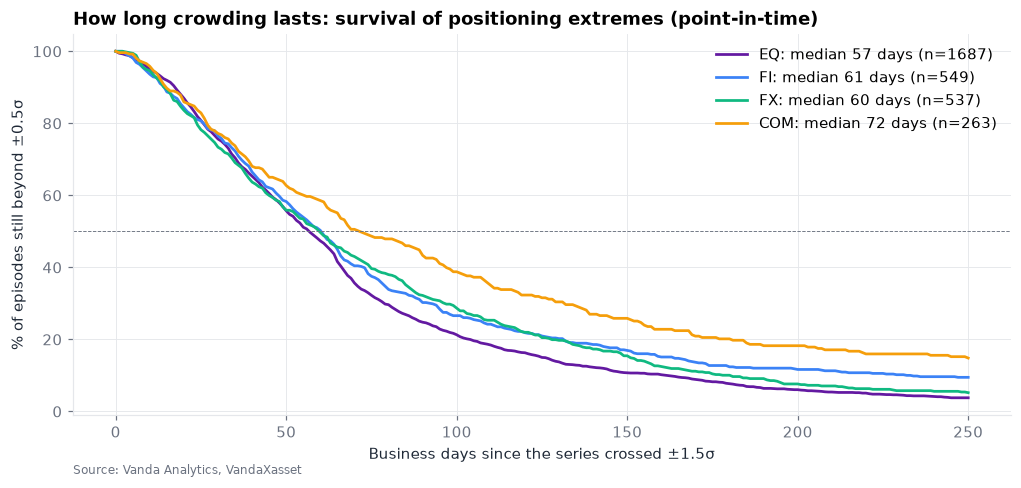

In [3]:
def survival(durations: pd.Series, censored: pd.Series, max_days: int = 250) -> pd.Series:
    """Kaplan-Meier: share of episodes still beyond ±0.5σ after t business days."""
    d, c = durations.fillna(max_days + 1).values, censored.values
    curve, alive = [], 1.0
    for t in range(max_days + 1):
        at_risk = (d >= t).sum()
        ended = ((d == t) & ~c).sum()
        alive *= 1 - ended / at_risk if at_risk else 1
        curve.append(alive)
    return pd.Series(curve)


def median_life(curve: pd.Series) -> float:
    below = curve[curve <= 0.5]
    return float(below.index[0]) if len(below) else np.nan


fig, ax = plt.subplots()
for asset, color in ASSET_COLORS.items():
    g = episodes[episodes.asset == asset]
    curve = survival(g.days_to_normal, g.censored)
    ax.plot(curve.index, curve * 100, color=color, lw=1.8, label=f"{asset}: median {median_life(curve):.0f} days (n={len(g)})")
ax.axhline(50, color=qk.VANDA["sub"], lw=0.6, ls="--")
ax.set_xlabel("Business days since the series crossed ±1.5σ")
ax.set_ylabel("% of episodes still beyond ±0.5σ")
ax.set_title("How long crowding lasts: survival of positioning extremes (point-in-time)")
ax.legend(loc="upper right")
qk.source_note(ax)
plt.show()

In [4]:
summary = episodes.groupby("asset").agg(
    episodes=("label", "size"),
    still_crowded_20d=("z_20d", lambda s: (s > qk.CROWDING_THRESHOLD).mean()),
    still_crowded_60d=("z_60d", lambda s: (s > qk.CROWDING_THRESHOLD).mean()),
    median_peak=("peak", "median"),
)
summary["median days to normal"] = [median_life(survival(g.days_to_normal, g.censored)) for _, g in episodes.groupby("asset")]
summary.round(2)

,episodes,still_crowded_20d,still_crowded_60d,median_peak,median days to normal
asset,,,,,
COM,263,0.36,0.19,1.88,72.0
EQ,1687,0.49,0.23,2.07,57.0
FI,549,0.45,0.26,2.09,61.0
FX,537,0.44,0.26,2.14,60.0


Crowding is **persistent**. A typical extreme takes months, not days, to normalise, and a large share of markets are
still beyond ±1.5σ a month after they first crossed. A threshold cross alone is therefore a poor timing signal for a
reversal: on the day it fires, most of the episode is still ahead.

## 3. The average episode

Lining up every episode on its crossing day shows the typical shape: how fast it builds, how far it overshoots, and how
it decays. Values are signed so that the crowded side is always positive.

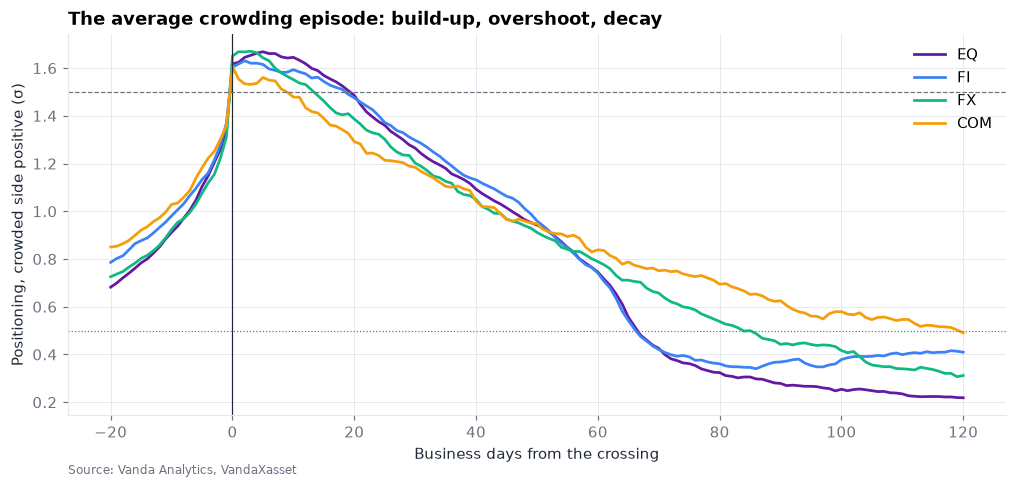

In [5]:
path_df = pd.concat(paths, axis=1)
assets = pd.Series([ref.at[label, "asset_type"] for label, _ in path_df.columns], index=path_df.columns)

fig, ax = plt.subplots()
for asset, color in ASSET_COLORS.items():
    cols = assets.index[assets == asset]
    if len(cols):
        ax.plot(path_df[cols].mean(axis=1), color=color, lw=1.8, label=asset)
ax.axvline(0, color=qk.VANDA["ink"], lw=0.8)
for level, style in [(qk.CROWDING_THRESHOLD, "--"), (NORMAL, ":")]:
    ax.axhline(level, color=qk.VANDA["sub"], lw=0.8, ls=style)
ax.set_xlabel("Business days from the crossing")
ax.set_ylabel("Positioning, crowded side positive (σ)")
ax.set_title("The average crowding episode: build-up, overshoot, decay")
ax.legend(loc="upper right")
qk.source_note(ax)
plt.show()

## 4. Longs vs shorts

In [6]:
side_table = pd.DataFrame({
    name: {
        "episodes": len(g),
        "median days to normal": median_life(survival(g.days_to_normal, g.censored)),
        "still crowded after 20d": (g.z_20d > qk.CROWDING_THRESHOLD).mean(),
        "median peak (σ)": g.peak.median(),
    }
    for name, g in [("crowded long", episodes[episodes.side == 1]), ("crowded short", episodes[episodes.side == -1])]
}).T
side_table.round(2)

,episodes,median days to normal,still crowded after 20d,median peak (σ)
crowded long,1559.0,55.0,0.46,2.14
crowded short,1477.0,65.0,0.46,2.00


## 5. Does the speed going in predict the way out?

`speed_in` is how far positioning moved over the 20 business days before the crossing. Are fast, sharp build-ups
shorter-lived than slow, grinding ones?

In [7]:
episodes["build-up"] = pd.qcut(episodes.speed_in, 3, labels=["slow build", "medium", "fast build"])
speed = pd.DataFrame({
    bucket: {
        "episodes": len(g),
        "median days to normal": median_life(survival(g.days_to_normal, g.censored)),
        "median peak (σ)": g.peak.median(),
        "still crowded after 20d": (g.z_20d > qk.CROWDING_THRESHOLD).mean(),
    }
    for bucket, g in episodes.groupby("build-up", observed=True)
}).T
speed.round(2)

,episodes,median days to normal,median peak (σ),still crowded after 20d
slow build,1012.0,59.0,1.90,0.37
medium,1012.0,64.0,2.05,0.48
fast build,1012.0,56.0,2.35,0.52


Fast build-ups **overshoot further**: they peak higher and are more often still beyond ±1.5σ after a month. But they
take about as long as slow ones to get back to normal. How quickly a crowd forms tells you how far it may run, not how
soon it will end.

## 6. Today's extremes in context

For every series currently beyond ±1.5σ: how long has the episode run, and what share of comparable past episodes (same
asset class and side) were still crowded at this age?

In [8]:
latest_date = panel.index.max()
current = []
for label in daily_labels:
    z = panel[label].dropna()
    if z.empty or (latest_date - z.index[-1]).days > 10 or abs(z.iloc[-1]) < qk.CROWDING_THRESHOLD:
        continue
    side = int(np.sign(z.iloc[-1]))
    inside = np.flatnonzero((z.values * side) < NORMAL)
    start = z.index[inside[-1] + 1] if len(inside) else z.index[0]
    age = len(z.loc[start:]) - 1
    asset = ref.at[label, "asset_type"]
    curve = survival(*[episodes.loc[(episodes.asset == asset) & (episodes.side == side), c] for c in ("days_to_normal", "censored")])
    current.append({
        "name": ref.at[label, "name"], "asset": asset, "z": z.iloc[-1], "episode age (days)": age,
        "past episodes still crowded at this age": curve.iloc[min(age, len(curve) - 1)],
    })

pd.DataFrame(current).sort_values("z").round(2)

,name,asset,z,episode age (days),past episodes still crowded at this age
0,Dubai Equity,EQ,-4.77,19,0.89
20,Taiwan Tech,EQ,-3.06,99,0.26
3,USDBRL,FX,-3.06,238,0.06
5,China H-Shares Materials,EQ,-2.28,59,0.52
13,Korea Cons. Disc,EQ,-2.17,59,0.52
23,US High Yield,FI,-2.09,30,0.79
6,Germany 2YR,FI,-2.03,26,0.81
4,USDCLP,FX,-1.94,118,0.25
1,Australia Equity,EQ,-1.84,58,0.52
11,Indonesia Equity,EQ,-1.78,11,0.95


### Takeaways

* **Extremes persist.** Expect months, not days, before an extreme normalises; a ±1.5σ cross is the start of an
  episode, not its end.
* **Overshoot is normal.** The typical episode peaks well beyond the threshold, so sizing should allow for positioning
  getting *more* crowded before it unwinds.
* **Age matters.** Section 6 turns the survival curves into a conditional view of current extremes: how unusual it is
  for an episode of this age to still be running.

Use this alongside notebook 03 (who is crowded now) and notebooks 06 and 08 (who the crowd is) to decide whether an
extreme is early, mature or overdue.

---
**Next:** `06 - Systematic Strategies - CTA, Risk Parity & Vol Targeting`.